In [1]:
import numpy as np
import pandas as pd
import re

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('gurgaon_properties_cleaned_v1.csv')

In [4]:
df.duplicated().sum()

np.int64(120)

In [5]:
df.head(1)
# focus is on -> areaWithType, additionalRoom, agePossession, furnishDetails, features 

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features
0,flat,adani oyster greens,sector 102,1.9,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,"pooja room,study room,store room",9.0,North-East,1 to 5 Year Old,"['MSK bedding products', 'INOX Gurgaon Dreamz Search Google Maps', 'Sheetla Mata Medical College', 'Prime Scholars International School', 'Sani mandir', 'Mata mandir', 'Gautam Hospital', 'ESIC Dispensary', 'RockPro Consulting', 'L.K ENERGY COMPANY HP PETROL PUMP', 'POWERGRID CORPORATION', 'Ramlal Nice Hotel', 'Skylark Cricket Academy', 'HUDA Sewage Treatment Plant', ""Colonel's Central Academy""]","['8 Fan', '7 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",NaN


In [6]:
#1. areaWithType


In [7]:
df.sample(5)[['price','area','areaWithType']]

,price,area,areaWithType
1207,1.80,2344.0,Carpet area: 2344 (217.76 sq.m.)
3198,13.50,7000.0,Built Up area: 7000 (650.32 sq.m.)
2531,1.17,1671.0,Super Built up area 1671(155.24 sq.m.)Built Up area: 1660 sq.ft. (154.22 sq.m.)Carpet area: 1650 sq.ft. (153.29 sq.m.)
3741,2.00,1310.0,Super Built up area 1310(121.7 sq.m.)
3623,1.42,1368.0,Built Up area: 1368 (127.09 sq.m.)


In [8]:
# This function extracts the Super Built up area
def get_super_built_up_area(text):
    match = re.search(r'Super Built up area (\d+\.?\d*)', text)
    if match:
        return float(match.group(1))
    return None

In [9]:
# This function extracts the Built Up area or Carpet area
def get_area(text, area_type):
    match = re.search(area_type + r'\s*:\s*(\d+\.?\d*)', text)
    if match:
        return float(match.group(1))
    return None

In [10]:
# This function checks if the area is provided in sq.m. and converts it to sqft if needed
def convert_to_sqft(text, area_value):
    if area_value is None:
        return None
    match = re.search(r'{} \((\d+\.?\d*) sq.m.\)'.format(area_value), text)
    if match:
        sq_m_value = float(match.group(1))
        return sq_m_value * 10.7639  # conversion factor from sq.m. to sqft
    return area_value

In [11]:
# Extract Super Built up area and convert to sqft if needed
df['super_built_up_area'] = df['areaWithType'].apply(get_super_built_up_area)
df['super_built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['super_built_up_area']), axis=1)

# Extract Built Up area and convert to sqft if needed
df['built_up_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Built Up area'))
df['built_up_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['built_up_area']), axis=1)

# Extract Carpet area and convert to sqft if needed
df['carpet_area'] = df['areaWithType'].apply(lambda x: get_area(x, 'Carpet area'))
df['carpet_area'] = df.apply(lambda x: convert_to_sqft(x['areaWithType'], x['carpet_area']), axis=1)

In [12]:
df[['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].sample(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
812,0.70,flat,1224.0,Built Up area: 1224 (113.71 sq.m.),NaN,1224.0,NaN
15,3.50,flat,2937.0,Built Up area: 2937 (272.86 sq.m.)Carpet area: 1762 sq.ft. (163.7 sq.m.),NaN,2937.0,1762.0
3099,2.60,flat,1766.0,Super Built up area 1630(151.43 sq.m.),1630.0,NaN,NaN
2364,0.29,house,891.0,Plot area 891(82.78 sq.m.),NaN,NaN,NaN
693,10.00,flat,4072.0,Super Built up area 4072(378.3 sq.m.)Built Up area: 3000 sq.ft. (278.71 sq.m.)Carpet area: 2800 sq.ft. (260.13 sq.m.),4072.0,3000.0,2800.0


In [13]:
df.duplicated().sum()

np.int64(120)

In [14]:
df[~((df['super_built_up_area'].isnull()) | (df['built_up_area'].isnull()) | (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].shape

(534, 7)

In [15]:
df[df['areaWithType'].str.contains('Plot')][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].head(5)

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
10,6.40,house,2700.0,Plot area 365(305.19 sq.m.)Built Up area: 366 sq.yards (306.02 sq.m.),NaN,366.0,NaN
22,16.00,house,4500.0,Plot area 500(418.06 sq.m.),NaN,NaN,NaN
31,0.65,house,70.0,Plot area 70(6.5 sq.m.),NaN,NaN,NaN
34,3.50,house,2250.0,Plot area 2050(190.45 sq.m.)Built Up area: 2250 sq.ft. (209.03 sq.m.),NaN,2250.0,NaN
40,7.25,house,360.0,Plot area 360(33.45 sq.m.),NaN,NaN,NaN


In [16]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    27
price_per_sqft           27
area                     27
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom            0
floorNum                 19
facing                 1116
agePossession             1
nearbyLocations         185
furnishDetails          988
features                647
super_built_up_area    1901
built_up_area          2622
carpet_area            1868
dtype: int64

In [17]:
all_nan_df = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']]

In [18]:
all_nan_df.head()

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
22,16.00,house,4500.0,Plot area 500(418.06 sq.m.),NaN,NaN,NaN
31,0.65,house,70.0,Plot area 70(6.5 sq.m.),NaN,NaN,NaN
40,7.25,house,360.0,Plot area 360(33.45 sq.m.),NaN,NaN,NaN
43,2.10,house,549.0,Plot area 61(51 sq.m.),NaN,NaN,NaN
59,2.99,house,1449.0,Plot area 161(134.62 sq.m.),NaN,NaN,NaN


In [19]:
all_nan_index = df[((df['super_built_up_area'].isnull()) & (df['built_up_area'].isnull()) & (df['carpet_area'].isnull()))][['price','property_type','area','areaWithType','super_built_up_area','built_up_area','carpet_area']].index

In [20]:
# Function to extract plot area from 'areaWithType' column
def extract_plot_area(area_with_type):
    match = re.search(r'Plot area (\d+\.?\d*)', area_with_type)
    return float(match.group(1)) if match else None

In [21]:
all_nan_df['built_up_area'] = all_nan_df['areaWithType'].apply(extract_plot_area)

# Update the original dataframe
#gurgaon_properties.update(filtered_rows)

In [22]:
all_nan_df

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
22,16.0000,house,4500.0,Plot area 500(418.06 sq.m.),NaN,500.00,NaN
31,0.6500,house,70.0,Plot area 70(6.5 sq.m.),NaN,70.00,NaN
40,7.2500,house,360.0,Plot area 360(33.45 sq.m.),NaN,360.00,NaN
43,2.1000,house,549.0,Plot area 61(51 sq.m.),NaN,61.00,NaN
59,2.9900,house,1449.0,Plot area 161(134.62 sq.m.),NaN,161.00,NaN
66,3.5000,house,2610.0,Plot area 290(242.48 sq.m.),NaN,290.00,NaN
67,2.1000,house,900.0,Plot area 100(83.61 sq.m.),NaN,100.00,NaN
70,3.5500,house,1449.0,Plot area 161(134.62 sq.m.),NaN,161.00,NaN
71,7.0000,house,5400.0,Plot area 600(501.68 sq.m.),NaN,600.00,NaN
78,3.9000,house,1836.0,Plot area 204(170.57 sq.m.),NaN,204.00,NaN


In [23]:
def convert_scale(row):
    if np.isnan(row['area']) or np.isnan(row['built_up_area']):
        return row['built_up_area']
    else:
        if round(row['area']/row['built_up_area']) == 9.0:
            return row['built_up_area'] * 9
        elif round(row['area']/row['built_up_area']) == 11.0:
            return row['built_up_area'] * 10.7
        else:
            return row['built_up_area']

In [24]:
all_nan_df['built_up_area'] = all_nan_df.apply(convert_scale,axis=1)

In [25]:
all_nan_df

,price,property_type,area,areaWithType,super_built_up_area,built_up_area,carpet_area
22,16.0000,house,4500.0,Plot area 500(418.06 sq.m.),NaN,4500.00,NaN
31,0.6500,house,70.0,Plot area 70(6.5 sq.m.),NaN,70.00,NaN
40,7.2500,house,360.0,Plot area 360(33.45 sq.m.),NaN,360.00,NaN
43,2.1000,house,549.0,Plot area 61(51 sq.m.),NaN,549.00,NaN
59,2.9900,house,1449.0,Plot area 161(134.62 sq.m.),NaN,1449.00,NaN
66,3.5000,house,2610.0,Plot area 290(242.48 sq.m.),NaN,2610.00,NaN
67,2.1000,house,900.0,Plot area 100(83.61 sq.m.),NaN,900.00,NaN
70,3.5500,house,1449.0,Plot area 161(134.62 sq.m.),NaN,1449.00,NaN
71,7.0000,house,5400.0,Plot area 600(501.68 sq.m.),NaN,5400.00,NaN
78,3.9000,house,1836.0,Plot area 204(170.57 sq.m.),NaN,1836.00,NaN


In [26]:
# update the original dataframe
df.update(all_nan_df)

In [27]:
df.isnull().sum()

property_type             0
society                   1
sector                    0
price                    27
price_per_sqft           27
area                     27
areaWithType              0
bedRoom                   0
bathroom                  0
balcony                   0
additionalRoom            0
floorNum                 19
facing                 1116
agePossession             1
nearbyLocations         185
furnishDetails          988
features                647
super_built_up_area    1901
built_up_area          2073
carpet_area            1868
dtype: int64

In [28]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,"pooja room,study room,store room",9.0,North-East,1 to 5 Year Old,"['MSK bedding products', 'INOX Gurgaon Dreamz Search Google Maps', 'Sheetla Mata Medical College', 'Prime Scholars International School', 'Sani mandir', 'Mata mandir', 'Gautam Hospital', 'ESIC Dispensary', 'RockPro Consulting', 'L.K ENERGY COMPANY HP PETROL PUMP', 'POWERGRID CORPORATION', 'Ramlal Nice Hotel', 'Skylark Cricket Academy', 'HUDA Sewage Treatment Plant', ""Colonel's Central Academy""]","['8 Fan', '7 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",NaN,NaN,NaN,1889.0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,not available,3.0,NaN,By 2023,"['Raheja Mall', 'HUDA Market, Sector 14', 'Gurgaon Road', 'Dwarka Expressway', 'RHM Public School', 'SGT University', 'Shri Balaji Multispeciality Hospital', 'Indira Gandhi International Airport', 'infinity Business Park', 'Park Inn, Gurgaon', 'Heritage badminton academy', 'SkyJumper Trampoline Park']",[],NaN,1440.0,NaN,NaN
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,not available,22.0,NaN,By 2023,"['Huda Metro Station (Gurugram)', 'Dwarka Expressway', 'Gurugram Global Heights School', 'DPG Institute of Technology', 'Signature Advanced Hospital', 'Indira Gandhi International Airport', 'iON Digital Zone, Gurgaon', 'IMT Manesar', 'Holiday Inn Gurugram Sector 90', 'SkyJumper Trampoline Park', 'Ramgarh Farms & Resort']",[],"['Private Garden / Terrace', 'Lift(s)', 'Swimming Pool', 'Park', 'Visitor Parking', 'Security Personnel', 'Shopping Centre', 'Fitness Centre / GYM']",1365.0,NaN,NaN
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet area: 1322 sq.ft. (122.82 sq.m.),3.0,4.0,3,servant room,22.0,North-East,1 to 5 Year Old,"['Airia Mall', 'Golf Corse Ext. Rd.', 'National Highway-48', 'Indus World School', 'Gurugram University', 'Ananta Hospital', 'Indira Gandhi International Airport', 'DLF Corporate Greens', 'IMT Manesar', 'Hyatt Regency Gurgaon', 'SkyJumper Trampoline Park']",[],"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",2350.0,NaN,1322.0
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,"pooja room,study room",4.0,East,1 to 5 Year Old,"['Yaduvanshi Shiksha Niketan Sector- 92', 'Aarvy Healthcare Hospital', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']","['1 Fan', '1 Exhaust Fan', '2 Geyser', '1 Light', '1 Modular Kitchen', '2 Wardrobe', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",NaN,NaN,591.0


In [29]:
#2.additionalRoom

In [30]:
df['additionalRoom'].value_counts()

additionalRoom
not available                                    1600
servant room                                      705
study room                                        250
others                                            225
pooja room                                        165
store room                                         99
study room,servant room                            99
pooja room,servant room                            82
pooja room,study room,servant room,store room      72
servant room,others                                60
pooja room,study room,servant room                 55
pooja room,study room,servant room,others          54
servant room,pooja room                            38
servant room,store room                            33
study room,others                                  29
pooja room,study room                              22
pooja room,others                                  17
pooja room,store room                              15
servant room,

In [31]:
# additional room
# List of new columns to be created
new_cols = ['study room', 'servant room', 'store room', 'pooja room', 'others']

# Populate the new columns based on the "additionalRoom" column
for col in new_cols:
    df[col] = df['additionalRoom'].str.contains(col).astype(int)

In [32]:
df.sample(5)[['additionalRoom','study room', 'servant room', 'store room', 'pooja room', 'others']]

,additionalRoom,study room,servant room,store room,pooja room,others
1193,"servant room,study room,pooja room",1,1,0,1,0
3782,"servant room,store room",0,1,1,0,0
470,not available,0,0,0,0,0
3056,study room,1,0,0,0,0
683,"servant room,study room",1,1,0,0,0


In [33]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,"pooja room,study room,store room",9.0,North-East,1 to 5 Year Old,"['MSK bedding products', 'INOX Gurgaon Dreamz Search Google Maps', 'Sheetla Mata Medical College', 'Prime Scholars International School', 'Sani mandir', 'Mata mandir', 'Gautam Hospital', 'ESIC Dispensary', 'RockPro Consulting', 'L.K ENERGY COMPANY HP PETROL PUMP', 'POWERGRID CORPORATION', 'Ramlal Nice Hotel', 'Skylark Cricket Academy', 'HUDA Sewage Treatment Plant', ""Colonel's Central Academy""]","['8 Fan', '7 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",NaN,NaN,NaN,1889.0,1,0,1,1,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,not available,3.0,NaN,By 2023,"['Raheja Mall', 'HUDA Market, Sector 14', 'Gurgaon Road', 'Dwarka Expressway', 'RHM Public School', 'SGT University', 'Shri Balaji Multispeciality Hospital', 'Indira Gandhi International Airport', 'infinity Business Park', 'Park Inn, Gurgaon', 'Heritage badminton academy', 'SkyJumper Trampoline Park']",[],NaN,1440.0,NaN,NaN,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,not available,22.0,NaN,By 2023,"['Huda Metro Station (Gurugram)', 'Dwarka Expressway', 'Gurugram Global Heights School', 'DPG Institute of Technology', 'Signature Advanced Hospital', 'Indira Gandhi International Airport', 'iON Digital Zone, Gurgaon', 'IMT Manesar', 'Holiday Inn Gurugram Sector 90', 'SkyJumper Trampoline Park', 'Ramgarh Farms & Resort']",[],"['Private Garden / Terrace', 'Lift(s)', 'Swimming Pool', 'Park', 'Visitor Parking', 'Security Personnel', 'Shopping Centre', 'Fitness Centre / GYM']",1365.0,NaN,NaN,0,0,0,0,0
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet area: 1322 sq.ft. (122.82 sq.m.),3.0,4.0,3,servant room,22.0,North-East,1 to 5 Year Old,"['Airia Mall', 'Golf Corse Ext. Rd.', 'National Highway-48', 'Indus World School', 'Gurugram University', 'Ananta Hospital', 'Indira Gandhi International Airport', 'DLF Corporate Greens', 'IMT Manesar', 'Hyatt Regency Gurgaon', 'SkyJumper Trampoline Park']",[],"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",2350.0,NaN,1322.0,0,1,0,0,0
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,"pooja room,study room",4.0,East,1 to 5 Year Old,"['Yaduvanshi Shiksha Niketan Sector- 92', 'Aarvy Healthcare Hospital', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']","['1 Fan', '1 Exhaust Fan', '2 Geyser', '1 Light', '1 Modular Kitchen', '2 Wardrobe', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",NaN,NaN,591.0,1,0,0,1,0


In [34]:
#3.agePossession

In [35]:
df['agePossession'].value_counts()

agePossession
1 to 5 Year Old        1676
5 to 10 Year Old        577
0 to 1 Year Old         532
undefined               340
10+ Year Old            311
Under Construction       90
Within 6 months          70
Within 3 months          26
2023-12-01 00:00:00      20
By 2023                  19
By 2024                  17
2024-12-01 00:00:00      15
2024-03-01 00:00:00      14
2023-08-01 00:00:00       7
2024-10-01 00:00:00       7
2024-01-01 00:00:00       7
2025-12-01 00:00:00       7
2024-06-01 00:00:00       5
2023-11-01 00:00:00       5
2024-08-01 00:00:00       4
By 2025                   4
2023-09-01 00:00:00       4
2024-07-01 00:00:00       4
2023-10-01 00:00:00       3
2024-11-01 00:00:00       3
2025-01-01 00:00:00       3
2024-02-01 00:00:00       3
2024-05-01 00:00:00       3
2025-03-01 00:00:00       2
2025-10-01 00:00:00       2
2027-06-01 00:00:00       2
2025-08-01 00:00:00       2
2027-07-01 00:00:00       2
2025-07-01 00:00:00       2
Dec 2023                  2
Jun 20

In [36]:
def categorize_age_possession(value):
    if pd.isna(value):
        return "Undefined"
    if "0 to 1 Year Old" in value or "Within 6 months" in value or "Within 3 months" in value:
        return "New Property"
    if "1 to 5 Year Old" in value:
        return "Relatively New"
    if "5 to 10 Year Old" in value:
        return "Moderately Old"
    if "10+ Year Old" in value:
        return "Old Property"
    if "Under Construction" in value or "By" in value:
        return "Under Construction"
    try:
        # For entries like 'May 2024'
        int(value.split(" ")[-1])
        return "Under Construction"
    except:
        return "Undefined"

In [37]:
df['agePossession'] = df['agePossession'].apply(categorize_age_possession)

In [38]:
df['agePossession'].value_counts()

agePossession
Relatively New        1676
New Property           628
Moderately Old         577
Undefined              484
Old Property           311
Under Construction     140
Name: count, dtype: int64

In [39]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,"pooja room,study room,store room",9.0,North-East,Relatively New,"['MSK bedding products', 'INOX Gurgaon Dreamz Search Google Maps', 'Sheetla Mata Medical College', 'Prime Scholars International School', 'Sani mandir', 'Mata mandir', 'Gautam Hospital', 'ESIC Dispensary', 'RockPro Consulting', 'L.K ENERGY COMPANY HP PETROL PUMP', 'POWERGRID CORPORATION', 'Ramlal Nice Hotel', 'Skylark Cricket Academy', 'HUDA Sewage Treatment Plant', ""Colonel's Central Academy""]","['8 Fan', '7 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",NaN,NaN,NaN,1889.0,1,0,1,1,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,not available,3.0,NaN,Under Construction,"['Raheja Mall', 'HUDA Market, Sector 14', 'Gurgaon Road', 'Dwarka Expressway', 'RHM Public School', 'SGT University', 'Shri Balaji Multispeciality Hospital', 'Indira Gandhi International Airport', 'infinity Business Park', 'Park Inn, Gurgaon', 'Heritage badminton academy', 'SkyJumper Trampoline Park']",[],NaN,1440.0,NaN,NaN,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,not available,22.0,NaN,Under Construction,"['Huda Metro Station (Gurugram)', 'Dwarka Expressway', 'Gurugram Global Heights School', 'DPG Institute of Technology', 'Signature Advanced Hospital', 'Indira Gandhi International Airport', 'iON Digital Zone, Gurgaon', 'IMT Manesar', 'Holiday Inn Gurugram Sector 90', 'SkyJumper Trampoline Park', 'Ramgarh Farms & Resort']",[],"['Private Garden / Terrace', 'Lift(s)', 'Swimming Pool', 'Park', 'Visitor Parking', 'Security Personnel', 'Shopping Centre', 'Fitness Centre / GYM']",1365.0,NaN,NaN,0,0,0,0,0
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet area: 1322 sq.ft. (122.82 sq.m.),3.0,4.0,3,servant room,22.0,North-East,Relatively New,"['Airia Mall', 'Golf Corse Ext. Rd.', 'National Highway-48', 'Indus World School', 'Gurugram University', 'Ananta Hospital', 'Indira Gandhi International Airport', 'DLF Corporate Greens', 'IMT Manesar', 'Hyatt Regency Gurgaon', 'SkyJumper Trampoline Park']",[],"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",2350.0,NaN,1322.0,0,1,0,0,0
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,"pooja room,study room",4.0,East,Relatively New,"['Yaduvanshi Shiksha Niketan Sector- 92', 'Aarvy Healthcare Hospital', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']","['1 Fan', '1 Exhaust Fan', '2 Geyser', '1 Light', '1 Modular Kitchen', '2 Wardrobe', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",NaN,NaN,591.0,1,0,0,1,0


In [40]:
#4.furnishDetails

In [41]:
df.sample(5)[['furnishDetails','features']]

,furnishDetails,features
304,[],"['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Visitor Parking', 'Swimming Pool', 'Park', 'Internet/wi-fi connectivity', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center', 'Water softening plant']"
171,NaN,['Club house / Community Center']
278,NaN,"['Feng Shui / Vaastu Compliant', 'Lift(s)', 'Park']"
722,"['3 Wardrobe', '4 Fan', '4 Light', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Private Garden / Terrace', 'High Ceiling Height', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking', 'Security Personnel', 'Low Density Society', 'Waste Disposal', 'Rain Water Harvesting']"
1130,"['1 Modular Kitchen', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Light', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']","['Security / Fire Alarm', 'Power Back-up', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Shopping Centre', 'Fitness Centre / GYM', 'Club house / Community Center']"


In [42]:
# Extract all unique furnishings from the furnishDetails column
all_furnishings = []
for detail in df['furnishDetails'].dropna():
    furnishings = detail.replace('[', '').replace(']', '').replace("'", "").split(', ')
    all_furnishings.extend(furnishings)
unique_furnishings = list(set(all_furnishings))

# Define a function to extract the count of a furnishing from the furnishDetails
def get_furnishing_count(details, furnishing):
    if isinstance(details, str):
        if f"No {furnishing}" in details:
            return 0
        pattern = re.compile(f"(\d+) {furnishing}")
        match = pattern.search(details)
        if match:
            return int(match.group(1))
        elif furnishing in details:
            return 1
    return 0

# Simplify the furnishings list by removing "No" prefix and numbers
columns_to_include = [re.sub(r'No |\d+', '', furnishing).strip() for furnishing in unique_furnishings]
columns_to_include = list(set(columns_to_include))  # Get unique furnishings
columns_to_include = [furnishing for furnishing in columns_to_include if furnishing]  # Remove empty strings

# Create new columns for each unique furnishing and populate with counts
for furnishing in columns_to_include:
    df[furnishing] = df['furnishDetails'].apply(lambda x: get_furnishing_count(x, furnishing))

# Create the new dataframe with the required columns
furnishings_df = df[['furnishDetails'] + columns_to_include]

In [43]:
furnishings_df.shape

(3816, 19)

In [44]:
furnishings_df.drop(columns=['furnishDetails'],inplace=True)

In [45]:
furnishings_df.sample(5)

,Sofa,Bed,Microwave,Fan,Dining Table,Water Purifier,Stove,Geyser,Curtains,Washing Machine,Modular Kitchen,Fridge,Wardrobe,Chimney,Light,Exhaust Fan,TV,AC
857,0,0,0,9,0,0,0,0,0,0,0,0,0,0,10,0,0,0
3330,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
180,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3
1332,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3525,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [46]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [47]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(furnishings_df)

In [48]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(scaled_data)
    wcss_reduced.append(kmeans.inertia_)

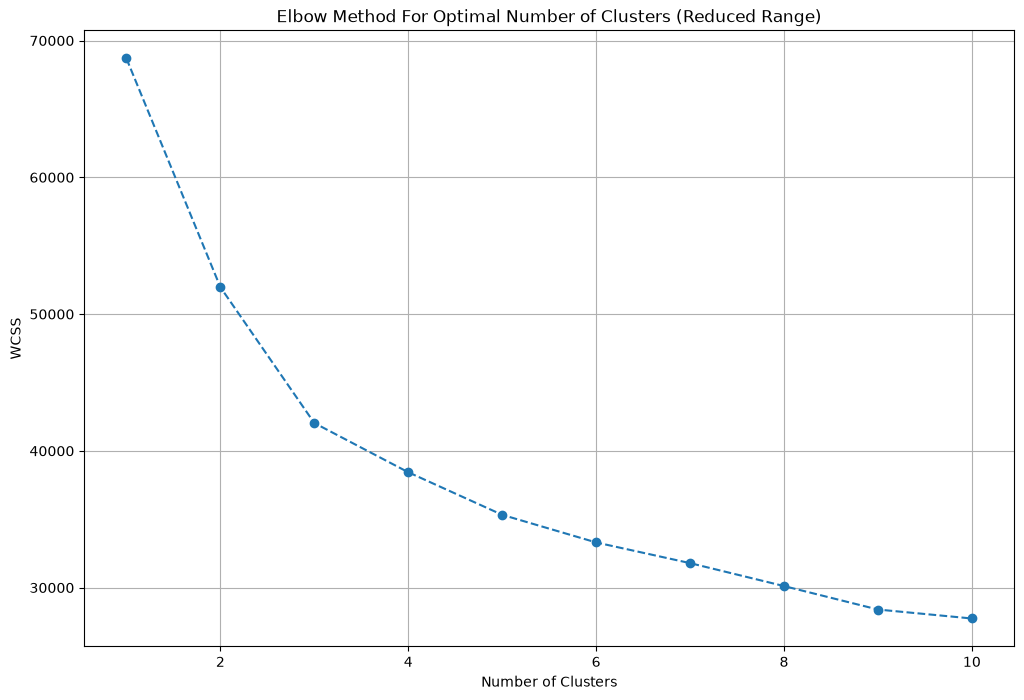

In [49]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [50]:
n_clusters = 3

# Fit the KMeans model
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(scaled_data)

# Predict the cluster assignments for each row
cluster_assignments = kmeans.predict(scaled_data)

In [51]:
df = df.iloc[:,:-18]

In [52]:
df['furnishing_type'] = cluster_assignments

In [53]:
df.sample(5)[['furnishDetails','furnishing_type']]
# 0 -> unfurnished
# 1 -> semifurnished
# 2 -> furnished

,furnishDetails,furnishing_type
2981,NaN,0
1797,"['1 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0
2704,"['1 Water Purifier', '1 Exhaust Fan', '5 Geyser', '8 AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Fan', 'No Modular Kitchen', 'No Light', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine']",2
3044,"['1 Light', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Fan', 'No Geyser', 'No Modular Kitchen', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",0
2233,"['5 Fan', '1 Exhaust Fan', '2 Geyser', '8 Light', '1 Chimney', '1 Modular Kitchen', '3 Wardrobe', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']",2


In [54]:
#5.features

In [55]:
df[['society','features']].sample(5)

,society,features
1978,signature global park,"['Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'No open drainage around', 'Piped-gas', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Shopping Centre', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting', 'Club house / Community Center']"
1363,orris aster court premier,"['Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']"
1467,professors enclave cghs,"['Feng Shui / Vaastu Compliant', 'Lift(s)', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Visitor Parking', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Fitness Centre / GYM', 'Waste Disposal', 'Rain Water Harvesting']"
2325,godrej oasis,"['Security / Fire Alarm', 'Power Back-up', 'Feng Shui / Vaastu Compliant', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Visitor Parking', 'Swimming Pool', 'Park', 'Shopping Centre', 'Fitness Centre / GYM', 'Rain Water Harvesting', 'Club house / Community Center']"
3793,sushant lok 1 builder floors,"['Water purifier', 'Centrally Air Conditioned', 'Security / Fire Alarm', 'Feng Shui / Vaastu Compliant', 'Private Garden / Terrace', 'High Ceiling Height', 'Maintenance Staff', 'False Ceiling Lighting', 'Water Storage', 'Separate entry for servant room', 'No open drainage around', 'Bank Attached Property', 'Piped-gas', 'Internet/wi-fi connectivity', 'Recently Renovated', 'Visitor Parking', 'Swimming Pool', 'Park', 'Security Personnel', 'Natural Light', 'Airy Rooms', 'Spacious Interiors', 'Low Density Society', 'Waste Disposal', 'Rain Water Harvesting', 'Fitness Centre / GYM', 'Club house / Community Center']"


In [56]:
df['features'].isnull().sum()

np.int64(647)

In [57]:
import pandas as pd
app_df = pd.read_csv('appartments.csv')
app_df.head(2)

,PropertyName,PropertySubName,NearbyLocations,LocationAdvantages,Link,PriceDetails,TopFacilities
0,Smartworld One DXP,"2, 3, 4 BHK Apartment in Sector 113, Gurgaon","['Bajghera Road', 'Palam Vihar Halt', 'DPSG Palam Vihar', 'Park Hospital', 'Gurgaon Railway Station']","{'Bajghera Road': '800 Meter', 'Palam Vihar Halt': '2.5 KM', 'DPSG Palam Vihar': '3.1 KM', 'Park Hospital': '3.1 KM', 'Gurgaon Railway Station': '4.9 KM', 'The NorthCap University': '5.4 KM', 'Dwarka Expy': '1.2 KM', 'Hyatt Place Gurgaon Udyog Vihar': '7.7 KM', 'Dwarka Sector 21, Metro Station': '7.2 KM', 'Pacific D21 Mall': '7.4 KM', 'Indira Gandhi International Airport': '14.7 KM', 'Hamoni Golf Camp': '6.2 KM', 'Fun N Food Waterpark': '8.8 KM', 'Accenture DDC5': '9 KM'}",https://www.99acres.com/smartworld-one-dxp-sector-113-gurgaon-npxid-r400415,"{'2 BHK': {'building_type': 'Apartment', 'area_type': 'Carpet Area', 'area': '1,370 sq.ft.', 'price-range': '₹ 2 - 2.4 Cr'}, '3 BHK': {'building_type': 'Apartment', 'area_type': 'Carpet Area', 'area': '1,850 - 2,050 sq.ft.', 'price-range': '₹ 2.25 - 3.59 Cr'}, '4 BHK': {'building_type': 'Apartment', 'area_type': 'Carpet Area', 'area': '2,600 sq.ft.', 'price-range': '₹ 3.24 - 4.56 Cr'}}","['Swimming Pool', 'Salon', 'Restaurant', 'Spa', 'Cafeteria', 'Sun Deck', '24x7 Security', 'Club House', 'Gated Community']"
1,M3M Crown,"3, 4 BHK Apartment in Sector 111, Gurgaon","['DPSG Palam Vihar Gurugram', 'The NorthCap University', 'Park Hospital, Palam Vihar', 'Pacific D21 Mall', 'Palam Vihar Halt Railway Station']","{'DPSG Palam Vihar Gurugram': '1.4 Km', 'The NorthCap University': '4.4 Km', 'Park Hospital, Palam Vihar': '1.4 Km', 'Pacific D21 Mall': '8.2 Km', 'Palam Vihar Halt Railway Station': '1.2 Km', 'Dwarka Sector 21 Metro Station': '8.1 Km', 'Dwarka Expressway': '450 m', 'Fun N Food Water Park': '8.1 Km', 'Indira Gandhi International Airport': '14.1 Km', 'Tau DeviLal Sports Complex': '11.2 Km', 'Hamoni Golf Camp': '5 Km', 'Hyatt Place': '6.1 Km', 'Altrade Business Centre': '11.2 Km'}",https://www.99acres.com/m3m-crown-sector-111-gurgaon-npxid-r404068,"{'3 BHK': {'building_type': 'Apartment', 'area_type': 'Super Built-up Area', 'area': '1,605 - 2,170 sq.ft.', 'price-range': '₹ 2.2 - 3.03 Cr'}, '4 BHK': {'building_type': 'Apartment', 'area_type': 'Super Built-up Area', 'area': '2,248 - 2,670 sq.ft.', 'price-range': '₹ 3.08 - 3.73 Cr'}}","['Bowling Alley', 'Mini Theatre', 'Manicured Garden', 'Swimming Pool', 'Flower Garden', 'Reading Lounge', 'Golf Course', 'Barbecue', 'Sauna']"


In [58]:
app_df['PropertyName'] = app_df['PropertyName'].str.lower()

In [59]:
temp_df = df[df['features'].isnull()]

In [60]:
temp_df.shape

(647, 26)

In [61]:
x = temp_df.merge(app_df,left_on='society',right_on='PropertyName',how='left')['TopFacilities']

In [62]:
df.loc[temp_df.index,'features'] = x.values

In [63]:
df['features'].isnull().sum()

np.int64(493)

In [64]:
from sklearn.preprocessing import MultiLabelBinarizer
import ast

In [65]:
# Convert the string representation of lists in the 'features' column to actual lists
df['features_list'] = df['features'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) and x.startswith('[') else [])

# Use MultiLabelBinarizer to convert the features list into a binary matrix
mlb = MultiLabelBinarizer()
features_binary_matrix = mlb.fit_transform(df['features_list'])

# Convert the binary matrix into a DataFrame
features_binary_df = pd.DataFrame(features_binary_matrix, columns=mlb.classes_)

In [66]:
features_binary_df.sample(5)

,24/7 Power Backup,24/7 Water Supply,24x7 Security,ATM,Aerobics Centre,Air Hockey,Airy Rooms,Amphitheatre,Automated Car Wash,Badminton Court,Bank Attached Property,Banquet Hall,Bar/Chill-Out Lounge,Barbecue,Basketball Court,Beach Volley Ball Court,Billiards,Bowling Alley,Bus Shelter,Business Lounge,CCTV Camera Security,Cafeteria,Car Parking,Car wash area,Card Room,Centrally Air Conditioned,Changing Area,Children's Play Area,Cigar Lounge,Clinic,Club House,Club house / Community Center,Community Hall,Concierge Service,Conference room,Creche/Day care,Cricket Pitch,Doctor on Call,Earthquake Resistant,Entrance Lobby,False Ceiling Lighting,Feng Shui / Vaastu Compliant,Fire Fighting Systems,Fitness Centre / GYM,Flower Garden,Food Court,Foosball,Football,Fountain,Gated Community,Gazebo,Golf Course,Grocery Shop,Gymnasium,High Ceiling Height,High Speed Elevators,Infinity Pool,Intercom Facility,Internal Street Lights,Internet/wi-fi connectivity,Jacuzzi,Jogging Track,Landscape Garden,Laundry,Lawn Tennis Court,Library,Lift(s),Lounge,Low Density Society,Maintenance Staff,Manicured Garden,Medical Centre,Milk Booth,Mini Theatre,Multipurpose Court,Multipurpose Hall,Natural Light,Natural Pond,No open drainage around,Park,Party Lawn,Pergola,Piped Gas,Piped-gas,Pool Table,Power Back up Lift,Power Back-up,Private Garden / Terrace,Property Staff,RO System,Rain Water Harvesting,Reading Lounge,Recently Renovated,Reflexology Park,Restaurant,Salon,Sauna,School,Security / Fire Alarm,Security Personnel,Separate entry for servant room,Sewage Treatment Plant,Shopping Centre,Skating Rink,Solar Lighting,Solar Water Heating,Spa,Spacious Interiors,Squash Court,Steam Room,Sun Deck,Swimming Pool,Temple,Terrace Garden,Theatre,Toddler Pool,Valet Parking,Vastu Compliant,Video Door Security,Visitor Parking,Visitors Parking,Volley Ball Court,Waiting Lounge,Waste Disposal,Water Softener Plant,Water Storage,Water purifier,Water softening plant,Wi-Fi Connectivity,Yoga/Meditation Area
2353,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0
2744,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
896,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
846,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0
1190,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0


In [67]:
features_binary_df.shape

(3816, 130)

In [68]:
wcss_reduced = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(features_binary_df)
    wcss_reduced.append(kmeans.inertia_)

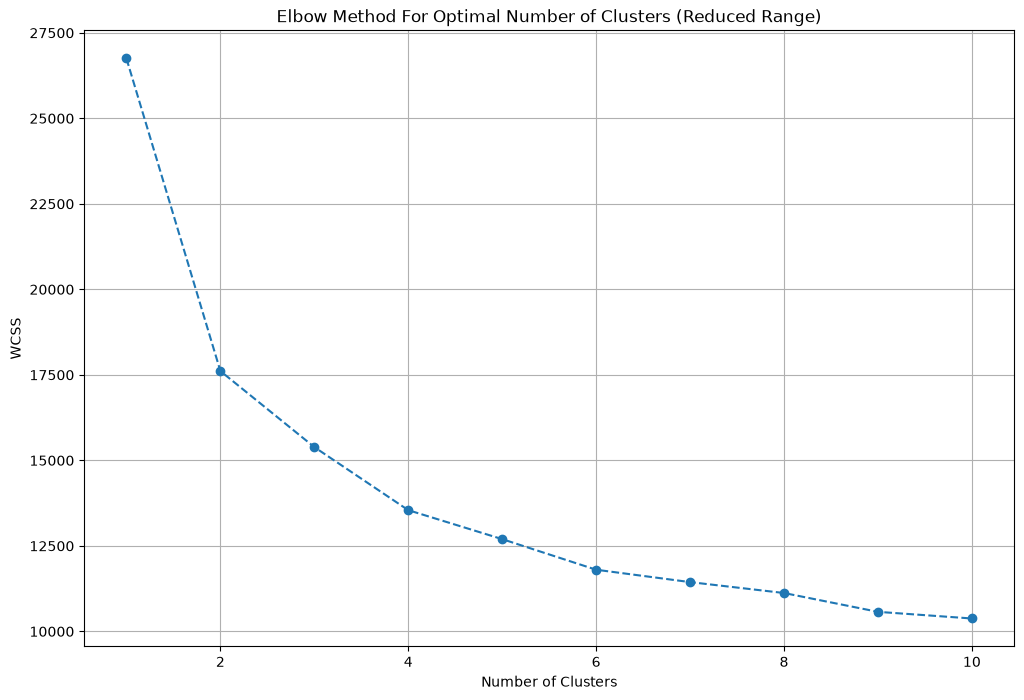

In [69]:
# Plot the results
plt.figure(figsize=(12, 8))
plt.plot(range(1,11), wcss_reduced, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal Number of Clusters (Reduced Range)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [70]:
# Define the weights for each feature as provided
# Assigning weights based on perceived luxury contribution
weights = {
    '24/7 Power Backup': 8,
    '24/7 Water Supply': 4,
    '24x7 Security': 7,
    'ATM': 4,
    'Aerobics Centre': 6,
    'Airy Rooms': 8,
    'Amphitheatre': 7,
    'Badminton Court': 7,
    'Banquet Hall': 8,
    'Bar/Chill-Out Lounge': 9,
    'Barbecue': 7,
    'Basketball Court': 7,
    'Billiards': 7,
    'Bowling Alley': 8,
    'Business Lounge': 9,
    'CCTV Camera Security': 8,
    'Cafeteria': 6,
    'Car Parking': 6,
    'Card Room': 6,
    'Centrally Air Conditioned': 9,
    'Changing Area': 6,
    "Children's Play Area": 7,
    'Cigar Lounge': 9,
    'Clinic': 5,
    'Club House': 9,
    'Concierge Service': 9,
    'Conference room': 8,
    'Creche/Day care': 7,
    'Cricket Pitch': 7,
    'Doctor on Call': 6,
    'Earthquake Resistant': 5,
    'Entrance Lobby': 7,
    'False Ceiling Lighting': 6,
    'Feng Shui / Vaastu Compliant': 5,
    'Fire Fighting Systems': 8,
    'Fitness Centre / GYM': 8,
    'Flower Garden': 7,
    'Food Court': 6,
    'Foosball': 5,
    'Football': 7,
    'Fountain': 7,
    'Gated Community': 7,
    'Golf Course': 10,
    'Grocery Shop': 6,
    'Gymnasium': 8,
    'High Ceiling Height': 8,
    'High Speed Elevators': 8,
    'Infinity Pool': 9,
    'Intercom Facility': 7,
    'Internal Street Lights': 6,
    'Internet/wi-fi connectivity': 7,
    'Jacuzzi': 9,
    'Jogging Track': 7,
    'Landscape Garden': 8,
    'Laundry': 6,
    'Lawn Tennis Court': 8,
    'Library': 8,
    'Lounge': 8,
    'Low Density Society': 7,
    'Maintenance Staff': 6,
    'Manicured Garden': 7,
    'Medical Centre': 5,
    'Milk Booth': 4,
    'Mini Theatre': 9,
    'Multipurpose Court': 7,
    'Multipurpose Hall': 7,
    'Natural Light': 8,
    'Natural Pond': 7,
    'Park': 8,
    'Party Lawn': 8,
    'Piped Gas': 7,
    'Pool Table': 7,
    'Power Back up Lift': 8,
    'Private Garden / Terrace': 9,
    'Property Staff': 7,
    'RO System': 7,
    'Rain Water Harvesting': 7,
    'Reading Lounge': 8,
    'Restaurant': 8,
    'Salon': 8,
    'Sauna': 9,
    'Security / Fire Alarm': 9,
    'Security Personnel': 9,
    'Separate entry for servant room': 8,
    'Sewage Treatment Plant': 6,
    'Shopping Centre': 7,
    'Skating Rink': 7,
    'Solar Lighting': 6,
    'Solar Water Heating': 7,
    'Spa': 9,
    'Spacious Interiors': 9,
    'Squash Court': 8,
    'Steam Room': 9,
    'Sun Deck': 8,
    'Swimming Pool': 8,
    'Temple': 5,
    'Theatre': 9,
    'Toddler Pool': 7,
    'Valet Parking': 9,
    'Video Door Security': 9,
    'Visitor Parking': 7,
    'Water Softener Plant': 7,
    'Water Storage': 7,
    'Water purifier': 7,
    'Yoga/Meditation Area': 7
}
# Calculate luxury score for each row
luxury_score = features_binary_df[list(weights.keys())].multiply(list(weights.values())).sum(axis=1)

In [71]:
df['luxury_score'] = luxury_score

In [72]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,features_list,luxury_score
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,"pooja room,study room,store room",9.0,North-East,Relatively New,"['MSK bedding products', 'INOX Gurgaon Dreamz Search Google Maps', 'Sheetla Mata Medical College', 'Prime Scholars International School', 'Sani mandir', 'Mata mandir', 'Gautam Hospital', 'ESIC Dispensary', 'RockPro Consulting', 'L.K ENERGY COMPANY HP PETROL PUMP', 'POWERGRID CORPORATION', 'Ramlal Nice Hotel', 'Skylark Cricket Academy', 'HUDA Sewage Treatment Plant', ""Colonel's Central Academy""]","['8 Fan', '7 Light', '1 Modular Kitchen', '1 Chimney', 'No AC', 'No Bed', 'No Curtains', 'No Dining Table', 'No Exhaust Fan', 'No Geyser', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Wardrobe', 'No Washing Machine', 'No Water Purifier']",NaN,NaN,NaN,1889.0,1,0,1,1,0,0,[],0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,not available,3.0,NaN,Under Construction,"['Raheja Mall', 'HUDA Market, Sector 14', 'Gurgaon Road', 'Dwarka Expressway', 'RHM Public School', 'SGT University', 'Shri Balaji Multispeciality Hospital', 'Indira Gandhi International Airport', 'infinity Business Park', 'Park Inn, Gurgaon', 'Heritage badminton academy', 'SkyJumper Trampoline Park']",[],NaN,1440.0,NaN,NaN,0,0,0,0,0,0,[],0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,not available,22.0,NaN,Under Construction,"['Huda Metro Station (Gurugram)', 'Dwarka Expressway', 'Gurugram Global Heights School', 'DPG Institute of Technology', 'Signature Advanced Hospital', 'Indira Gandhi International Airport', 'iON Digital Zone, Gurgaon', 'IMT Manesar', 'Holiday Inn Gurugram Sector 90', 'SkyJumper Trampoline Park', 'Ramgarh Farms & Resort']",[],"['Private Garden / Terrace', 'Lift(s)', 'Swimming Pool', 'Park', 'Visitor Parking', 'Security Personnel', 'Shopping Centre', 'Fitness Centre / GYM']",1365.0,NaN,NaN,0,0,0,0,0,0,"[Private Garden / Terrace, Lift(s), Swimming Pool, Park, Visitor Parking, Security Personnel, Shopping Centre, Fitness Centre / GYM]",56
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet area: 1322 sq.ft. (122.82 sq.m.),3.0,4.0,3,servant room,22.0,North-East,Relatively New,"['Airia Mall', 'Golf Corse Ext. Rd.', 'National Highway-48', 'Indus World School', 'Gurugram University', 'Ananta Hospital', 'Indira Gandhi International Airport', 'DLF Corporate Greens', 'IMT Manesar', 'Hyatt Regency Gurgaon', 'SkyJumper Trampoline Park']",[],"['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Water Storage', 'Park', 'Visitor Parking']",2350.0,NaN,1322.0,0,1,0,0,0,0,"[Feng Shui / Vaastu Compliant, Security / Fire Alarm, Intercom Facility, Lift(s), Maintenance Staff, Water Storage, Park, Visitor Parking]",49
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,"pooja room,study room",4.0,East,Relatively New,"['Yaduvanshi Shiksha Niketan Sector- 92', 'Aarvy Healthcare Hospital', 'Holiday Inn Gurugram Sector 90', 'Flying Wings Badminton Academy']","['1 Fan', '1 Exhaust Fan', '2 Geyser', '1 Light', '1 Modular Kitchen', '2 Wardrobe', 'No AC', 'No Bed', 'No Chimney', 'No Curtains', 'No Dining Table', 'No Microwave', 'No Fridge', 'No Sofa', 'No Stove', 'No TV', 'No Washing Machine', 'No Water Purifier']","['Feng Shui / Vaastu Compliant', 'Security / Fire Alarm', 'Intercom Facility', 'Lift(s)', 'Maintenance Staff', 'Park', 'Visitor Parking']",NaN,NaN,591.0,1,0,0,1,0,2,"[Feng Shui / Vaastu Compliant, Security / 

In [73]:
# cols to drop -> nearbyLocations,furnishDetails, features,features_list, additionalRoom
df.drop(columns=['nearbyLocations','furnishDetails','features','features_list','additionalRoom'],inplace=True)

In [74]:
df.sample(5)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
1931,flat,eldeco accolade,sohna road,0.725,4975.0,1457.0,Super Built up area 1457(135.36 sq.m.)Carpet area: 849 sq.ft. (78.87 sq.m.),2.0,2.0,3+,12.0,East,Relatively New,1457.0,NaN,849.0,1,0,0,0,0,0,152
872,flat,experion windchants,sector 112,2.600,10651.0,2441.0,Super Built up area 2441(226.78 sq.m.)Built Up area: 1939.03 sq.ft. (180.14 sq.m.),2.0,2.0,3,8.0,North-East,Relatively New,2441.0,1939.03,NaN,0,0,0,0,0,0,168
3096,house,independent,sector 69,0.800,10484.0,763.0,Built Up area: 763 (70.89 sq.m.),1.0,1.0,0,1.0,NaN,Undefined,NaN,763.00,NaN,0,0,0,0,0,0,0
1870,house,nul,sector 28,12.500,51440.0,2430.0,Plot area 270(225.75 sq.m.),16.0,17.0,3+,4.0,South,Relatively New,NaN,2430.00,NaN,1,1,0,1,1,1,137
20,flat,mapsko paradise,sector 83,0.950,6300.0,1508.0,Carpet area: 1340 (124.49 sq.m.),3.0,3.0,3,1.0,NaN,Moderately Old,NaN,NaN,1340.0,0,0,0,0,0,0,0


In [75]:
df.shape

(3816, 23)

In [76]:
df.to_csv('gurgaon_properties_cleaned_v2.csv',index=False)